# EDA: age and photos per person

Filtering applied on top of the team's cleaned dataset:
- Removed 95 photos with impossible ages (<0 or >100), from 42 people
- Removed 7 people left with only one distinct age after that
- Final: ~129.8k photos, ~8.1k people

In [40]:
import pandas as pd

df = pd.read_csv("../data/age.csv")
print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df.describe(include="all"))

(129943, 4)
['name', 'directory', 'age', 'gender']
                  name                                          directory  \
0  'Weird Al' Yankovic  imdb_crop/48/nm0946148_rm1093319424_1959-10-23...   
1  'Weird Al' Yankovic  imdb_crop/48/nm0946148_rm1126873856_1959-10-23...   
2  'Weird Al' Yankovic  imdb_crop/48/nm0946148_rm1956049664_1959-10-23...   
3  'Weird Al' Yankovic  imdb_crop/48/nm0946148_rm3125254656_1959-10-23...   
4  'Weird Al' Yankovic  imdb_crop/48/nm0946148_rm3591961856_1959-10-23...   

   age  gender  
0   30       1  
1   30       1  
2   56       1  
3   30       1  
4   56       1  
                  name                                          directory  \
count           129943                                             129943   
unique            8127                                             129943   
top     Angelina Jolie  imdb_crop/48/nm0946148_rm1093319424_1959-10-23...   
freq               330                                                  1   

In [41]:
bad = df[(df["age"] < 0) | (df["age"] > 100)]
print("Bad rows:", len(bad), "| people affected:", bad["name"].nunique())
print(df["age"].lt(0).sum(), "negative |", df["age"].gt(100).sum(), "over 100")
print(bad.sort_values("age").head(10)[["name", "age", "directory"]])
print(bad.sort_values("age").tail(10)[["name", "age", "directory"]])

Bad rows: 95 | people affected: 42
88 negative | 7 over 100
                  name  age                                          directory
11011   Barbara Palvin  -30  imdb_crop/80/nm5435980_rm1770170112_1993-10-8_...
9680     Ashley Benson  -24  imdb_crop/64/nm1667364_rm1214618112_1989-12-18...
9683     Ashley Benson  -24  imdb_crop/64/nm1667364_rm1466276352_1989-12-18...
9682     Ashley Benson  -24  imdb_crop/64/nm1667364_rm1449499136_1989-12-18...
9681     Ashley Benson  -24  imdb_crop/64/nm1667364_rm1432721920_1989-12-18...
102903   Rachel Melvin  -20  imdb_crop/93/nm1560493_rm3143997952_1985-2-9_1...
102904   Rachel Melvin  -20  imdb_crop/93/nm1560493_rm3160775168_1985-2-9_1...
39857       Farah Fath  -19  imdb_crop/41/nm0268841_rm1348835840_1984-5-1_1...
39858       Farah Fath  -19  imdb_crop/41/nm0268841_rm1365613056_1984-5-1_1...
39860       Farah Fath  -19  imdb_crop/41/nm0268841_rm1600494080_1984-5-1_1...
                    name  age  \
24140         Clay Aiken   -3   
86269

In [42]:
df_clean = df[(df["age"] >= 0) & (df["age"] <= 100)].copy()
print(len(df), "->", len(df_clean))

129943 -> 129848


In [43]:
per_person = df_clean.groupby("name").agg(
    photos=("age", "size"),
    distinct_ages=("age", "nunique"),
    age_span=("age", lambda s: s.max() - s.min()),
)
print(per_person.head())
print(per_person.describe())

                     photos  distinct_ages  age_span
name                                                
'Weird Al' Yankovic       6              3        26
50 Cent                  51             12        16
A.J. Buckley              9              5        10
A.J. Cook                10              2         2
A.J. Langer               6              4        21
            photos  distinct_ages     age_span
count  8127.000000    8127.000000  8127.000000
mean     15.977359       4.882614    11.787868
std      24.481650       3.878445    10.388623
min       1.000000       1.000000     0.000000
25%       3.000000       2.000000     4.000000
50%       7.000000       3.000000     9.000000
75%      17.000000       6.000000    16.000000
max     330.000000      36.000000    63.000000


In [44]:
one_age = per_person[per_person["distinct_ages"] == 1]
print(len(one_age), "people with only one distinct age")
print(one_age.sort_values("photos", ascending=False).head(10))

7 people with only one distinct age
                 photos  distinct_ages  age_span
name                                            
David Fumero          2              1         0
Heather Lindell       2              1         0
Barbara Palvin        1              1         0
Farah Fath            1              1         0
Moms Mabley           1              1         0
Tamie Sheffield       1              1         0
Vanessa Bayer         1              1         0


In [45]:
keep = per_person[per_person["distinct_ages"] >= 2].index
df_clean = df_clean[df_clean["name"].isin(keep)].copy()
print(len(df_clean), "photos |", df_clean["name"].nunique(), "people")

129839 photos | 8120 people


In [46]:
per_person = df_clean.groupby("name").agg(
    photos=("age", "size"),
    distinct_ages=("age", "nunique"),
    age_span=("age", lambda s: s.max() - s.min()),
)
print(per_person.describe())

            photos  distinct_ages    age_span
count  8120.000000    8120.000000  8120.00000
mean     15.990025       4.885961    11.79803
std      24.488395       3.878440    10.38733
min       2.000000       2.000000     1.00000
25%       3.000000       2.000000     4.00000
50%       7.000000       3.000000     9.00000
75%      17.000000       6.000000    16.00000
max     330.000000      36.000000    63.00000


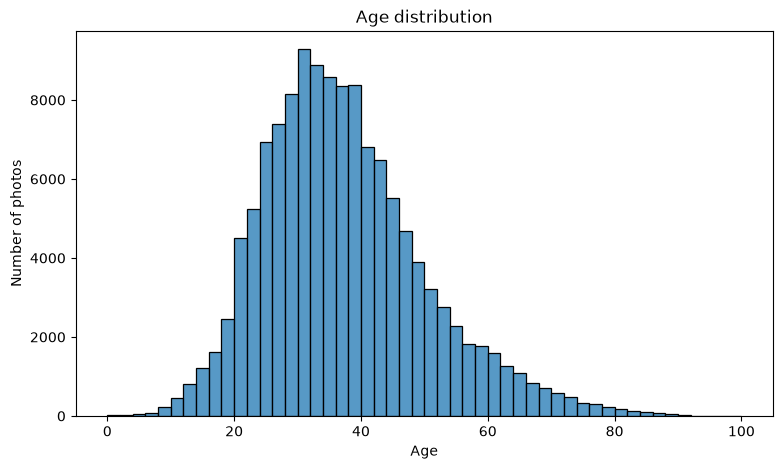

In [47]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("figures", exist_ok=True)

plt.figure(figsize=(9, 5))
sns.histplot(df_clean["age"], bins=range(0, 101, 2))
plt.title("Age distribution")
plt.xlabel("Age")
plt.ylabel("Number of photos")
plt.savefig("figures/age_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

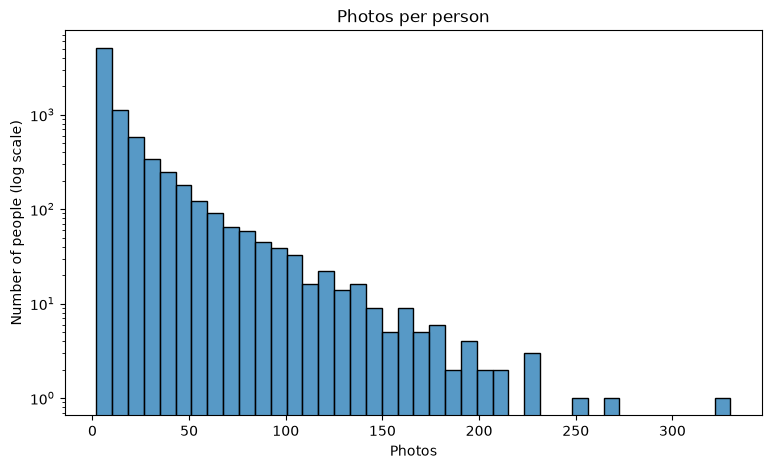

In [48]:
plt.figure(figsize=(9, 5))
sns.histplot(per_person["photos"], bins=40)
plt.yscale("log")
plt.title("Photos per person")
plt.xlabel("Photos")
plt.ylabel("Number of people (log scale)")
plt.savefig("figures/photos_per_person.png", dpi=150, bbox_inches="tight")
plt.show()

In [49]:
print(f"{(per_person['photos'] <= 10).mean():.1%} of people have 10 or fewer photos")
print(f"{(per_person['photos'] >= 100).sum():,} people with 100+ photos")
print(f"Under 15: {(df_clean['age'] < 15).mean():.1%} | Over 70: {(df_clean['age'] > 70).mean():.1%}")
print(f"Median age: {df_clean['age'].median():.1f}")

62.6% of people have 10 or fewer photos
154 people with 100+ photos
Under 15: 1.7% | Over 70: 1.7%
Median age: 35.0


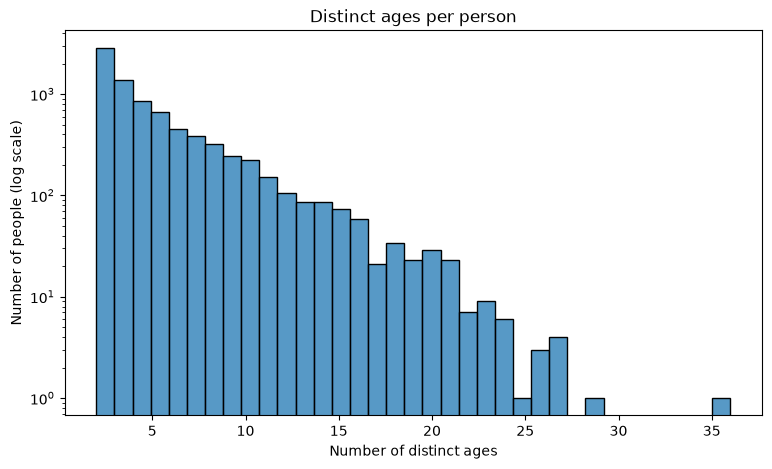

In [50]:
plt.figure(figsize=(9, 5))
sns.histplot(per_person["distinct_ages"], bins=35)
plt.yscale("log")
plt.title("Distinct ages per person")
plt.xlabel("Number of distinct ages")
plt.ylabel("Number of people (log scale)")
plt.savefig("figures/distinct_ages_per_person.png", dpi=150, bbox_inches="tight")
plt.show()

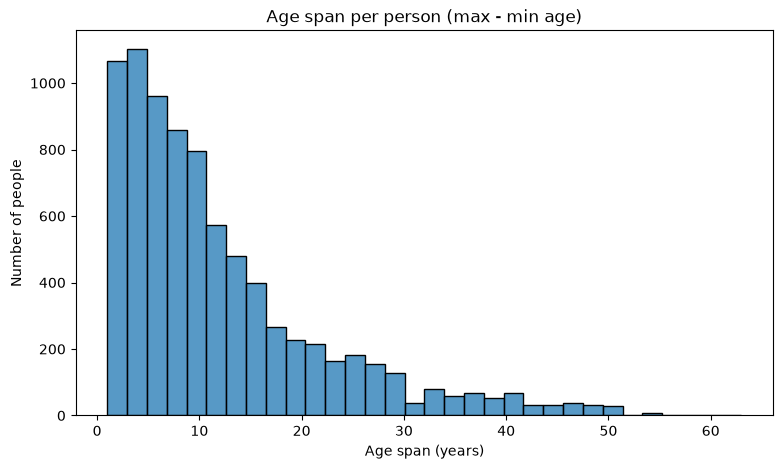

In [51]:
plt.figure(figsize=(9, 5))
sns.histplot(per_person["age_span"], bins=32)
plt.title("Age span per person (max - min age)")
plt.xlabel("Age span (years)")
plt.ylabel("Number of people")
plt.savefig("figures/age_span_per_person.png", dpi=150, bbox_inches="tight")
plt.show()

In [52]:
# 1. Distinct ages
print(f"{(per_person['distinct_ages'] <= 3).mean():.1%} have 3 or fewer distinct ages")
print(f"{(per_person['distinct_ages'] >= 10).mean():.1%} people with 10+ distinct ages")
print(f"Median distinct ages per person: {per_person['distinct_ages'].median():.1f}\n\n")

# 2. Age span
print(f"{(per_person['age_span'] <= 5).mean():.1%} have an age span <= 5 years")
print(f"{(per_person['age_span'] >= 20).mean():.1%} have an age span >= 20 years")
print(f"{(per_person['age_span'] >= 30).mean():.1%} of people with age span 30+ years")
print(f"Median age span per person: {per_person['age_span'].median():.1f}\n\n")

52.2% have 3 or fewer distinct ages
11.7% people with 10+ distinct ages
Median distinct ages per person: 3.0


32.6% have an age span <= 5 years
18.4% have an age span >= 20 years
7.5% of people with age span 30+ years
Median age span per person: 9.0




In [53]:
df_clean["gender_label"] = df_clean["gender"].map({1: "Male", 0: "Female"})
per_person = df_clean.groupby("name").agg(
    photos=("age", "size"),
    distinct_ages=("age", "nunique"),
    age_span=("age", lambda s: s.max() - s.min()),
    gender=("gender_label", "first"),
)
print(per_person.head())

                     photos  distinct_ages  age_span  gender
name                                                        
'Weird Al' Yankovic       6              3        26    Male
50 Cent                  51             12        16    Male
A.J. Buckley              9              5        10    Male
A.J. Cook                10              2         2  Female
A.J. Langer               6              4        21  Female


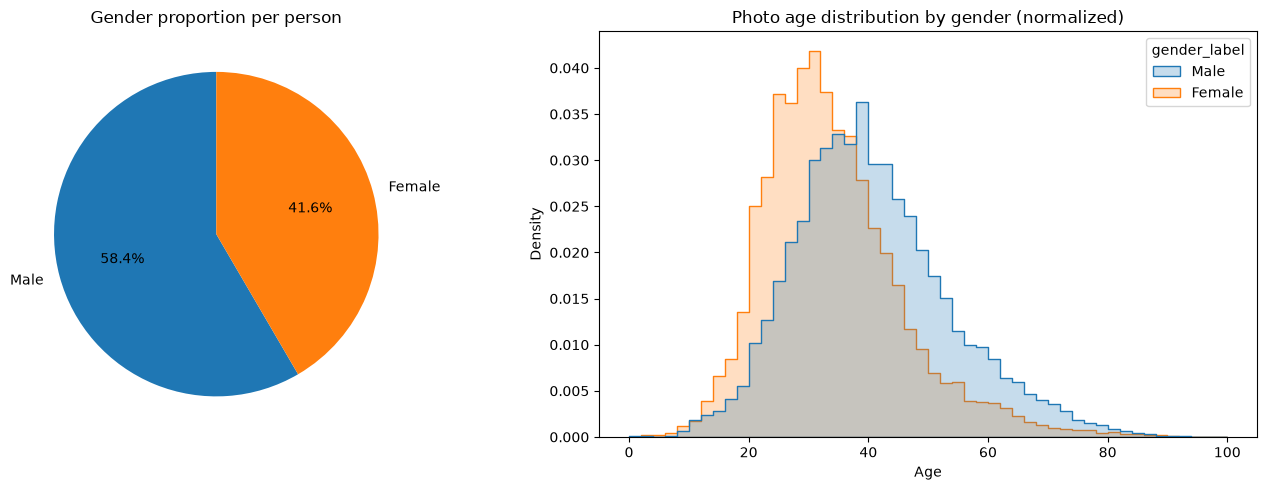

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
gender_counts = per_person["gender"].value_counts()
axes[0].pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90,
)
axes[0].set_title("Gender proportion per person")
sns.histplot(
    data=df_clean,
    x="age",
    hue="gender_label",
    bins=range(0, 101, 2),
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[1],
)
axes[1].set_title("Photo age distribution by gender (normalized)")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Density")
plt.tight_layout()
plt.savefig("figures/gender_and_age_summary.png", dpi=150, bbox_inches="tight")
plt.show()

## Key observations
- Ages are right-skewed, peaking around 30-34 with a median of 35. Most photos are of people aged 20-50.
- Children (<15) and older adults (>70) are rare: each makes up only about 1.7% of photos. A model trained on this data will likely be weakest at producing very old faces, which matters for the aging task.
- Photos per person are heavily skewed: about 63% of people have 10 or fewer photos, while 154 people have 100+ (max 330). Training on all photos as-is would let a small group of celebrities dominate, so consider capping photos per person.
- Distinct ages per person is left-skewed, meaning that most individuals have only a handful of photos of different ages. about 52% of individuals appear at 3 or fewer distinct ages (median 3 years).
- Nearly a third of individuals (32.6%) have an age span of 5 years or less between their youngest and oldest photo (median 9 years). Only 18.4% of people span 20+ years and among them, 7.5% of people span 30+ years (max 63 years), meaning the dataset mostly captures short-term aging rather than multi-decade transformations.
- Gender is roughly split with a proportion of 6:4 for Male to Female. Female photos skew noticeably younger—peaking around ages 28–32 with a sharp drop-off after 40—whereas male photos peak later around ages 38–40 and maintain much stronger representation into ages 50–75.
- Ethnicity is not labeled in this dataset, so it can't be analyzed. 